# COMP 4930SEF Task 1 - Transfer Learning and Attention on CIFAR-100 (50 Classes)

In [1]:
%env TF_CPP_MIN_LOG_LEVEL=2

env: TF_CPP_MIN_LOG_LEVEL=2


In this task, you'll work on:

- transfer learning with pre-trained CNNs (MobileNet, ResNet50, and EfficientNetB0),
- attention modules (CBAM and BAM) using serialization-safe Keras layers,
- two-stage training (warmup and controlled fine-tuning), and
- model comparison and evaluation on a 50-class CIFAR-100 animal and human subset.

## Utility code

This section contains constants, the provided CIFAR-100 subset loader, custom attention/preprocessing layers, and training utilities.

The following code defines key constants for image dimensions, batch size, number of classes, and training epochs.

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers, regularizers

IMG_WIDTH, IMG_HEIGHT = 224, 224 # input size expected by pre-trained backbones
NUM_CLASSES = 50 # 50 animals and people classes
BATCH_SIZE = 128
WARMUP_EPOCHS = 6
FINETUNE_EPOCHS = 14

The following code from the project guideline loads the 50-class CIFAR-100 animals and people subset and maps class indices to the range `0` to `49`.

In [3]:
ANIMALS_PEOPLE_INDICES = [
    1, 2, 3, 4,
    6, 7,
    11, 14, 15,
    18,
    19,
    21, 24,
    26,
    27,
    29,
    30, 31,
    32,
    34,
    35, 36, 38,
    42, 43,
    44,
    45,
    46,
    50, 55,
    57,
    63, 64,
    65,
    66,
    67,
    72, 73,
    74,
    75,
    77, 78, 79,
    80,
    91, 93, 95,
    97,
    98, 99,
]
import numpy as np
from tensorflow import keras
from tensorflow.keras.datasets import cifar100

def select_animals_people(y):
    """Returns a boolean mask for selecting animals/people in y"""
    return np.isin(np.ravel(y), ANIMALS_PEOPLE_INDICES)

def compress_animals_people_indices(y):
    """Maps indices in y to range 0 to 49"""
    out = np.zeros(100)
    for i, index in enumerate(ANIMALS_PEOPLE_INDICES):
        out[index] = i
    return out[y]

def load_cifar100_animals_people():
    """Loads a subset of CIFAR100 of animals and people"""
    (X_train, y_train), (X_test, y_test) = cifar100.load_data()
    mask_train = select_animals_people(y_train)
    X_train, y_train = X_train[mask_train], y_train[mask_train]
    mask_test = select_animals_people(y_test)
    X_test, y_test = X_test[mask_test], y_test[mask_test]
    y_train = compress_animals_people_indices(y_train)
    y_test = compress_animals_people_indices(y_test)
    return X_train, y_train, X_test, y_test

This helper function converts NumPy image and label arrays into `tf.data.Dataset` objects for memory-efficient batching and prefetching.

In [4]:
def make_tf_dataset(X, y, batch_size=BATCH_SIZE, shuffle=False):
    ds = tf.data.Dataset.from_tensor_slices((X, y))
    if shuffle:
        ds = ds.shuffle(buffer_size=len(X), seed=42, reshuffle_each_iteration=True)
    ds = ds.batch(batch_size).prefetch(tf.data.AUTOTUNE)
    return ds

The following custom layers implement serialization-safe backbone input preprocessing (`BackbonePreprocess`) and attention modules (`CBAMBlock` and `BAMBlock`), avoiding `Lambda` layers so models can be saved and reloaded cleanly.

In [5]:
@keras.utils.register_keras_serializable()
class BackbonePreprocess(layers.Layer):
    def __init__(self, backbone_type="mobilenet", **kwargs):
        super().__init__(**kwargs)
        self.backbone_type = backbone_type

    def call(self, inputs):
        x = tf.cast(inputs, tf.float32)
        if self.backbone_type == "mobilenet":
            return (x / 127.5) - 1.0 # scale [0, 255] to [-1, 1]
        elif self.backbone_type == "resnet50":
            x = x[..., ::-1] # RGB to BGR
            mean = tf.constant([103.939, 116.779, 123.68], dtype=tf.float32)
            return x - mean
        elif self.backbone_type == "efficientnet":
            return x # EfficientNetB0 includes internal rescaling
        else:
            raise ValueError(f"Unsupported backbone_type: {self.backbone_type}")

    def get_config(self):
        config = super().get_config()
        config.update({"backbone_type": self.backbone_type})
        return config


@keras.utils.register_keras_serializable()
class CBAMBlock(layers.Layer):
    def __init__(self, ratio=16, kernel_size=7, **kwargs):
        super().__init__(**kwargs)
        self.ratio = ratio
        self.kernel_size = kernel_size

    def build(self, input_shape):
        channels = int(input_shape[-1])
        reduced = max(channels // self.ratio, 1)
        # Shared MLP for channel attention
        self.shared_dense_1 = layers.Dense(reduced, activation="relu")
        self.shared_dense_2 = layers.Dense(channels)
        # Spatial attention convolution
        self.spatial_conv = layers.Conv2D(
            1, kernel_size=self.kernel_size, padding="same", activation="sigmoid"
        )
        super().build(input_shape)

    def call(self, inputs):
        # Channel attention branch
        avg_pool = tf.reduce_mean(inputs, axis=[1, 2], keepdims=True)
        max_pool = tf.reduce_max(inputs, axis=[1, 2], keepdims=True)
        avg_out = self.shared_dense_2(self.shared_dense_1(avg_pool))
        max_out = self.shared_dense_2(self.shared_dense_1(max_pool))
        ch_att = tf.nn.sigmoid(avg_out + max_out)
        x = inputs * ch_att

        # Spatial attention branch
        sp_avg = tf.reduce_mean(x, axis=-1, keepdims=True)
        sp_max = tf.reduce_max(x, axis=-1, keepdims=True)
        sp_concat = tf.concat([sp_avg, sp_max], axis=-1)
        sp_att = self.spatial_conv(sp_concat)
        return x * sp_att

    def get_config(self):
        config = super().get_config()
        config.update({"ratio": self.ratio, "kernel_size": self.kernel_size})
        return config


@keras.utils.register_keras_serializable()
class BAMBlock(layers.Layer):
    def __init__(self, ratio=16, dilation_rate=4, **kwargs):
        super().__init__(**kwargs)
        self.ratio = ratio
        self.dilation_rate = dilation_rate

    def build(self, input_shape):
        channels = int(input_shape[-1])
        reduced = max(channels // self.ratio, 1)
        # Channel attention branch
        self.ch_dense_1 = layers.Dense(reduced, activation="relu")
        self.ch_dense_2 = layers.Dense(channels)
        self.ch_bn = layers.BatchNormalization()

        # Spatial attention branch with dilated convolutions
        self.sp_conv_1 = layers.Conv2D(reduced, kernel_size=1, activation="relu")
        self.sp_conv_2 = layers.Conv2D(
            reduced, kernel_size=3, padding="same",
            dilation_rate=self.dilation_rate, activation="relu"
        )
        self.sp_conv_3 = layers.Conv2D(
            reduced, kernel_size=3, padding="same",
            dilation_rate=self.dilation_rate, activation="relu"
        )
        self.sp_conv_4 = layers.Conv2D(1, kernel_size=1)
        self.sp_bn = layers.BatchNormalization()
        super().build(input_shape)

    def call(self, inputs):
        # Channel branch
        avg_pool = tf.reduce_mean(inputs, axis=[1, 2], keepdims=True)
        ch_att = self.ch_bn(self.ch_dense_2(self.ch_dense_1(avg_pool)))

        # Spatial branch
        sp = self.sp_conv_1(inputs)
        sp = self.sp_conv_2(sp)
        sp = self.sp_conv_3(sp)
        sp_att = self.sp_bn(self.sp_conv_4(sp))

        # Residual attention fusion
        att_map = tf.nn.sigmoid(ch_att + sp_att)
        return inputs + inputs * att_map

    def get_config(self):
        config = super().get_config()
        config.update({"ratio": self.ratio, "dilation_rate": self.dilation_rate})
        return config

These utility functions retrieve final epoch metrics, plot training and validation histories, build models with the regularized classification head, and execute the two-stage transfer learning schedule.

In [6]:
def history_final_values(history):
    return {k: round(v[-1], 4) for k, v in history.history.items() if k in ["loss", "val_loss", "acc", "val_acc"]}

def plot_history(history_warmup, history_finetune=None):
    if history_finetune is None:
        df = pd.DataFrame(history_warmup.history)
    else:
        combined = {}
        for k in ["loss", "val_loss", "acc", "val_acc"]:
            combined[k] = history_warmup.history[k] + history_finetune.history[k]
        df = pd.DataFrame(combined)
    df.index = df.index + 1
    fig, axs = plt.subplots(1, 2, figsize=(8, 4))
    df.plot(y=["loss", "val_loss"], grid=True, ax=axs[0])
    df.plot(y=["acc", "val_acc"], grid=True, ax=axs[1])
    if history_finetune is not None:
        split_epoch = len(history_warmup.history["loss"])
        axs[0].axvline(split_epoch, color="gray", linestyle="--", linewidth=1)
        axs[1].axvline(split_epoch, color="gray", linestyle="--", linewidth=1)
    plt.tight_layout();

# Data augmentation block applied during training
data_augmentation = keras.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.1),
], name="data_augmentation")

def build_transfer_model(base_model, backbone_type, attention_layer=None, model_name="transfer_model"):
    base_model.trainable = False # freeze backbone for warmup
    inputs = layers.Input(shape=(32, 32, 3))
    x = layers.Resizing(IMG_HEIGHT, IMG_WIDTH, interpolation="bilinear")(inputs) # resize image width and height
    x = data_augmentation(x)
    x = BackbonePreprocess(backbone_type=backbone_type)(x)
    x = base_model(x, training=False)
    if attention_layer is not None:
        x = attention_layer(x)

    # Regularized classification head
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.BatchNormalization()(x)
    x = layers.Dropout(0.5)(x)
    x = layers.Dense(256, activation="relu", kernel_regularizer=regularizers.l2(1e-4))(x)
    x = layers.BatchNormalization()(x)
    x = layers.Dropout(0.5)(x)
    outputs = layers.Dense(NUM_CLASSES, activation="softmax")(x)

    return keras.Model(inputs, outputs, name=model_name)

def compile_and_fit_two_stage(model, base_model, train_ds, val_ds, unfreeze_layers,
                              warmup_epochs=WARMUP_EPOCHS, finetune_epochs=FINETUNE_EPOCHS):
    # Stage 1: Feature extraction warmup (frozen backbone)
    base_model.trainable = False
    callbacks_1 = [
        keras.callbacks.EarlyStopping(monitor="val_loss", patience=4, restore_best_weights=True),
        keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=2, min_lr=1e-6),
    ]
    model.compile(loss="categorical_crossentropy",
                  optimizer=keras.optimizers.Adam(learning_rate=1e-3),
                  metrics=["acc"])
    hist_1 = model.fit(train_ds, epochs=warmup_epochs, verbose=2,
                       validation_data=val_ds, callbacks=callbacks_1)

    # Stage 2: Controlled fine-tuning (unfreeze top layers, keep BatchNorm frozen)
    base_model.trainable = True
    for layer in base_model.layers[:-unfreeze_layers]:
        layer.trainable = False
    for layer in base_model.layers[-unfreeze_layers:]:
        if isinstance(layer, layers.BatchNormalization):
            layer.trainable = False

    callbacks_2 = [
        keras.callbacks.EarlyStopping(monitor="val_loss", patience=4, restore_best_weights=True),
        keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=2, min_lr=1e-6),
    ]
    model.compile(loss="categorical_crossentropy",
                  optimizer=keras.optimizers.Adam(learning_rate=1e-4),
                  metrics=["acc"])
    hist_2 = model.fit(train_ds, epochs=finetune_epochs, verbose=2,
                       validation_data=val_ds, callbacks=callbacks_2)

    return hist_1, hist_2

## Preparing the dataset

Let's load the CIFAR-100 animals and people subset using `load_cifar100_animals_people()`, split the 25,000 training images into an 80/20 stratified train/validation split, one-hot encode the labels, and build the `tf.data` pipelines.

In [7]:
from sklearn.model_selection import train_test_split

keras.utils.set_random_seed(42)
X_train_full, y_train_full, X_test, y_test_raw = load_cifar100_animals_people()

y_train_idx_full = np.ravel(y_train_full).astype(np.int32)
y_test_idx = np.ravel(y_test_raw).astype(np.int32)

# Stratified 80/20 train/validation split
X_train, X_val, y_train_idx, y_val_idx = train_test_split(
    X_train_full, y_train_idx_full, test_size=0.2,
    random_state=42, stratify=y_train_idx_full
)

y_train = keras.utils.to_categorical(y_train_idx, NUM_CLASSES) # one-hot encode
y_val = keras.utils.to_categorical(y_val_idx, NUM_CLASSES)
y_test = keras.utils.to_categorical(y_test_idx, NUM_CLASSES)

print("Train:", X_train.shape, y_train.shape)
print("Val:  ", X_val.shape, y_val.shape)
print("Test: ", X_test.shape, y_test.shape)

train_ds = make_tf_dataset(X_train, y_train, batch_size=BATCH_SIZE, shuffle=True)
val_ds = make_tf_dataset(X_val, y_val, batch_size=BATCH_SIZE, shuffle=False)
test_ds = make_tf_dataset(X_test, y_test, batch_size=BATCH_SIZE, shuffle=False)

169001437/169001437 ━━━━━━━━━━━━━━━━━━━━ 562s 3us/step
Train: (20000, 32, 32, 3) (20000, 50)
Val:   (5000, 32, 32, 3) (5000, 50)
Test:  (5000, 32, 32, 3) (5000, 50)


Validation results of all three candidate models are stored in a dictionary called `final_values`, and trained models are stored in `trained_models` for selecting the best model later.

In [8]:
from sklearn.metrics import f1_score

final_values = {}
trained_models = {}

def evaluate_val_metrics(model, hist_2):
    res = history_final_values(hist_2)
    y_probs = model.predict(val_ds, verbose=0)
    y_pred = np.argmax(y_probs, axis=1) # reverse one-hot encoding
    res["val_macro_f1"] = round(float(f1_score(y_val_idx, y_pred, average="macro")), 4)
    res["val_weighted_f1"] = round(float(f1_score(y_val_idx, y_pred, average="weighted")), 4)
    return res

## Model 1: Transfer learning with MobileNet

The first model uses a pre-trained MobileNet backbone without attention, unfreezing the top 25 layers during Stage 2 fine-tuning.

17225924/17225924 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step
Epoch 1/6
157/157 - 44s - 280ms/step - acc: 0.2110 - loss: 3.3729 - val_acc: 0.4924 - val_loss: 1.9308 - learning_rate: 0.0010
Epoch 2/6
157/157 - 31s - 199ms/step - acc: 0.3666 - loss: 2.4107 - val_acc: 0.5526 - val_loss: 1.6513 - learning_rate: 0.0010
Epoch 3/6
157/157 - 32s - 204ms/step - acc: 0.4100 - loss: 2.1890 - val_acc: 0.5698 - val_loss: 1.5606 - learning_rate: 0.0010
Epoch 4/6
157/157 - 32s - 203ms/step - acc: 0.4380 - loss: 2.0760 - val_acc: 0.5792 - val_loss: 1.5031 - learning_rate: 0.0010
Epoch 5/6
157/157 - 32s - 203ms/step - acc: 0.4564 - loss: 1.9890 - val_acc: 0.5884 - val_loss: 1.4739 - learning_rate: 0.0010
Epoch 6/6
157/157 - 32s - 204ms/step - acc: 0.4699 - loss: 1.9467 - val_acc: 0.5988 - val_loss: 1.4461 - learning_rate: 0.0010
Epoch 1/14
157/157 - 47s - 298ms/step - acc: 0.4354 - loss: 2.0467 - val_acc: 0.5018 - val_loss: 1.7970 - learning_rate: 1.0000e-04
Epoch 2/14
157/157 - 39s - 251ms/step - acc: 0.4678 - l

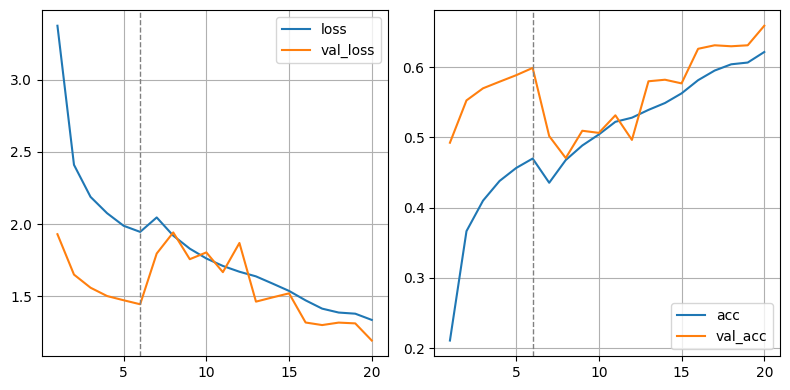

In [9]:
from tensorflow.keras.applications import mobilenet

keras.utils.set_random_seed(42)
base_model = mobilenet.MobileNet(
    weights="imagenet", include_top=False,
    input_shape=(IMG_HEIGHT, IMG_WIDTH, 3)
)
model = build_transfer_model(
    base_model, backbone_type="mobilenet",
    attention_layer=None, model_name="MobileNet_Baseline"
)
hist_1, hist_2 = compile_and_fit_two_stage(
    model, base_model, train_ds, val_ds, unfreeze_layers=25
)
final_values[model.name] = evaluate_val_metrics(model, hist_2)
trained_models[model.name] = model
print(final_values[model.name])
plot_history(hist_1, hist_2)

## Model 2: Transfer learning with ResNet50 and CBAM

The second model attaches a CBAM attention block (`ratio=16`, `kernel_size=7`) to ResNet50 and unfreezes the top 30 backbone layers during fine-tuning.

94765736/94765736 ━━━━━━━━━━━━━━━━━━━━ 3s 0us/step
Epoch 1/6
157/157 - 121s - 772ms/step - acc: 0.2537 - loss: 3.1757 - val_acc: 0.5572 - val_loss: 1.6125 - learning_rate: 0.0010
Epoch 2/6
157/157 - 99s - 630ms/step - acc: 0.4283 - loss: 2.1611 - val_acc: 0.6126 - val_loss: 1.3948 - learning_rate: 0.0010
Epoch 3/6
157/157 - 99s - 628ms/step - acc: 0.4760 - loss: 1.9355 - val_acc: 0.6282 - val_loss: 1.3434 - learning_rate: 0.0010
Epoch 4/6
157/157 - 99s - 628ms/step - acc: 0.4983 - loss: 1.8381 - val_acc: 0.6294 - val_loss: 1.3377 - learning_rate: 0.0010
Epoch 5/6
157/157 - 99s - 628ms/step - acc: 0.5144 - loss: 1.7465 - val_acc: 0.6420 - val_loss: 1.2713 - learning_rate: 0.0010
Epoch 6/6
157/157 - 99s - 627ms/step - acc: 0.5304 - loss: 1.6997 - val_acc: 0.6444 - val_loss: 1.2705 - learning_rate: 0.0010
Epoch 1/14
157/157 - 130s - 825ms/step - acc: 0.5707 - loss: 1.5370 - val_acc: 0.6816 - val_loss: 1.1384 - learning_rate: 1.0000e-04
Epoch 2/14
157/157 - 114s - 726ms/step - acc: 0.6346 

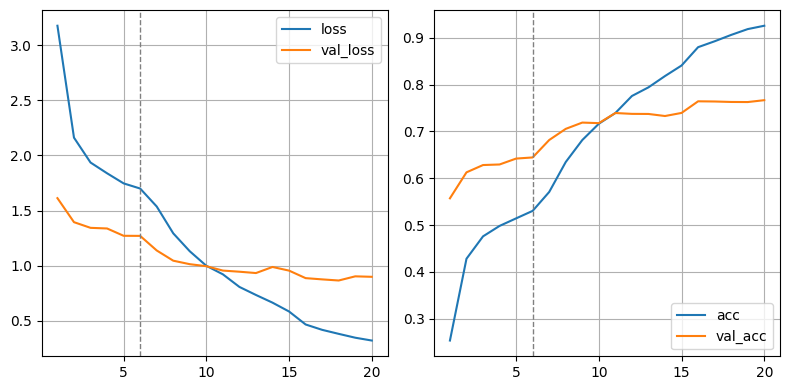

In [10]:
from tensorflow.keras.applications import resnet50

keras.utils.set_random_seed(42)
base_model = resnet50.ResNet50(
    weights="imagenet", include_top=False,
    input_shape=(IMG_HEIGHT, IMG_WIDTH, 3)
)
model = build_transfer_model(
    base_model, backbone_type="resnet50",
    attention_layer=CBAMBlock(ratio=16, kernel_size=7),
    model_name="ResNet50_CBAM"
)
hist_1, hist_2 = compile_and_fit_two_stage(
    model, base_model, train_ds, val_ds, unfreeze_layers=30
)
final_values[model.name] = evaluate_val_metrics(model, hist_2)
trained_models[model.name] = model
print(final_values[model.name])
plot_history(hist_1, hist_2)

## Model 3: Transfer learning with EfficientNetB0 and BAM

The third model attaches a BAM attention block (`ratio=16`, `dilation_rate=4`) to EfficientNetB0 and unfreezes the top 40 backbone layers during fine-tuning.

16705208/16705208 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step
Epoch 1/6
157/157 - 74s - 474ms/step - acc: 0.2853 - loss: 3.0021 - val_acc: 0.5940 - val_loss: 1.6063 - learning_rate: 0.0010
Epoch 2/6
157/157 - 52s - 333ms/step - acc: 0.4396 - loss: 2.1046 - val_acc: 0.6332 - val_loss: 1.3558 - learning_rate: 0.0010
Epoch 3/6
157/157 - 52s - 333ms/step - acc: 0.4884 - loss: 1.8903 - val_acc: 0.6492 - val_loss: 1.2655 - learning_rate: 0.0010
Epoch 4/6
157/157 - 52s - 333ms/step - acc: 0.5181 - loss: 1.7638 - val_acc: 0.6646 - val_loss: 1.2136 - learning_rate: 0.0010
Epoch 5/6
157/157 - 52s - 333ms/step - acc: 0.5362 - loss: 1.6897 - val_acc: 0.6688 - val_loss: 1.1823 - learning_rate: 0.0010
Epoch 6/6
157/157 - 52s - 334ms/step - acc: 0.5425 - loss: 1.6537 - val_acc: 0.6750 - val_loss: 1.1670 - learning_rate: 0.0010
Epoch 1/14
157/157 - 78s - 500ms/step - acc: 0.5917 - loss: 1.4670 - val_acc: 0.7086 - val_loss: 1.0350 - learning_rate: 1.0000e-04
Epoch 2/14
157/157 - 58s - 369ms/step - acc: 0.6238 - l

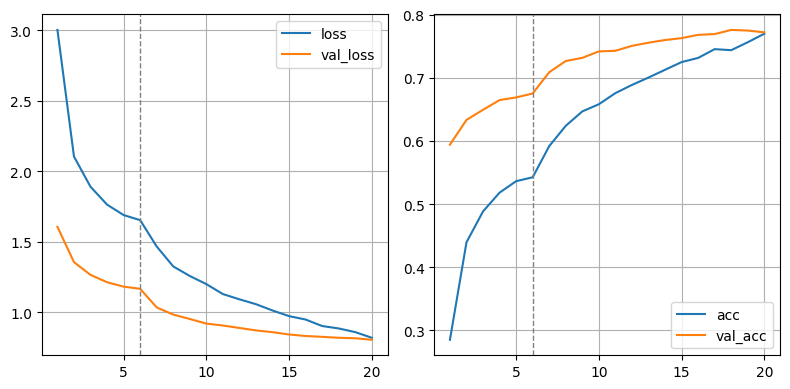

In [11]:
from tensorflow.keras.applications import efficientnet

keras.utils.set_random_seed(42)
base_model = efficientnet.EfficientNetB0(
    weights="imagenet", include_top=False,
    input_shape=(IMG_HEIGHT, IMG_WIDTH, 3)
)
model = build_transfer_model(
    base_model, backbone_type="efficientnet",
    attention_layer=BAMBlock(ratio=16, dilation_rate=4),
    model_name="EfficientNetB0_BAM"
)
hist_1, hist_2 = compile_and_fit_two_stage(
    model, base_model, train_ds, val_ds, unfreeze_layers=40
)
final_values[model.name] = evaluate_val_metrics(model, hist_2)
trained_models[model.name] = model
print(final_values[model.name])
plot_history(hist_1, hist_2)

## Model comparison and selection

The validation results of the three candidate models are displayed in a table below.

In [12]:
results_df = pd.DataFrame.from_dict(final_values, orient="index")
results_df

,acc,loss,val_acc,val_loss,val_macro_f1,val_weighted_f1
MobileNet_Baseline,0.6215,1.3378,0.6588,1.1951,0.6568,0.6568
ResNet50_CBAM,0.9255,0.3216,0.7666,0.8994,0.7643,0.7643
EfficientNetB0_BAM,0.7696,0.8199,0.7718,0.8056,0.7702,0.7702


Based on validation accuracy (`val_acc`), we select the best model, save it in `.keras` format, and inspect its architecture summary.

In [13]:
best_name = results_df["val_acc"].idxmax()
best_model = trained_models[best_name]
print("Selected best model:", best_name)
best_model.save("best_cifar100_50_model.keras")
best_model.summary()

Selected best model: EfficientNetB0_BAM


Model: "EfficientNetB0_BAM"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_6 (InputLayer)      │ (None, 32, 32, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ resizing_2 (Resizing)           │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ data_augmentation (Sequential)  │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ backbone_preprocess_2           │ (None, 224, 224, 3)    │             0 │
│ (BackbonePreprocess)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ efficientnetb0 (Functional)     │ (None, 7, 7, 1280)     │     4,049,571 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bam_block (BAMBlock)            │ (None, 7, 7, 1280)     │       429,205 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_2      │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_6           │ (None, 1280)           │         5,120 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_4 (Dropout)             │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_8 (Dense)                 │ (None, 256)            │       327,936 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_7           │ (None, 256)            │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_5 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_9 (Dense)                 │ (None, 50)             │        12,850 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 10,441,750 (39.83 MB)

 Trainable params: 2,808,021 (10.71 MB)

 Non-trainable params: 2,017,685 (7.70 MB)

 Optimizer params: 5,616,044 (21.42 MB)

## Final evaluation on the test set

The selected best model is evaluated on the held-out test set using loss, accuracy, macro/weighted F1 scores, and per-class accuracy.

In [14]:
from sklearn.metrics import classification_report

test_loss, test_acc = best_model.evaluate(test_ds, verbose=0)
y_probs = best_model.predict(test_ds, verbose=0)
y_pred = np.argmax(y_probs, axis=1) # reverse one-hot encoding

test_macro_f1 = f1_score(y_test_idx, y_pred, average="macro")
test_weighted_f1 = f1_score(y_test_idx, y_pred, average="weighted")

print(f"Test Loss:        {test_loss:.4f}")
print(f"Test Accuracy:    {test_acc:.4f}")
print(f"Test Macro F1:    {test_macro_f1:.4f}")
print(f"Test Weighted F1: {test_weighted_f1:.4f}")

Test Loss:        0.8400
Test Accuracy:    0.7630
Test Macro F1:    0.7627
Test Weighted F1: 0.7627


In [15]:
target_names = [f"class_{i} (orig_{orig_id})" for i, orig_id in enumerate(ANIMALS_PEOPLE_INDICES)]
print(classification_report(y_test_idx, y_pred, target_names=target_names, digits=4))

# Per-class accuracy summary
per_class_rows = []
for cls_idx, orig_id in enumerate(ANIMALS_PEOPLE_INDICES):
    mask = (y_test_idx == cls_idx)
    cls_acc = float(np.mean(y_pred[mask] == y_test_idx[mask]))
    per_class_rows.append({"class_id": cls_idx, "orig_cifar100_id": orig_id, "test_acc": round(cls_acc, 4)})

per_class_df = pd.DataFrame(per_class_rows).sort_values("test_acc", ascending=False)
print("Top 5 classes:")
display(per_class_df.head(5))
print("Bottom 5 classes:")
display(per_class_df.tail(5))

                    precision    recall  f1-score   support

  class_0 (orig_1)     0.8558    0.8900    0.8725       100
  class_1 (orig_2)     0.6752    0.7900    0.7281       100
  class_2 (orig_3)     0.7375    0.5900    0.6556       100
  class_3 (orig_4)     0.5500    0.6600    0.6000       100
  class_4 (orig_6)     0.8842    0.8400    0.8615       100
  class_5 (orig_7)     0.8351    0.8100    0.8223       100
 class_6 (orig_11)     0.6364    0.5600    0.5957       100
 class_7 (orig_14)     0.9149    0.8600    0.8866       100
 class_8 (orig_15)     0.8476    0.8900    0.8683       100
 class_9 (orig_18)     0.8261    0.7600    0.7917       100
class_10 (orig_19)     0.8000    0.7600    0.7795       100
class_11 (orig_21)     0.8214    0.9200    0.8679       100
class_12 (orig_24)     0.9175    0.8900    0.9036       100
class_13 (orig_26)     0.7315    0.7900    0.7596       100
class_14 (orig_27)     0.6140    0.7000    0.6542       100
class_15 (orig_29)     0.8039    0.8200

,class_id,orig_cifar100_id,test_acc
30,30,57,0.94
11,11,21,0.92
24,24,43,0.92
21,21,36,0.90
12,12,24,0.89


Bottom 5 classes:


,class_id,orig_cifar100_id,test_acc
2,2,3,0.59
6,6,11,0.56
36,36,72,0.56
32,32,64,0.54
20,20,35,0.45
